In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

from tqdm import tqdm
import pygpcca

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


In [2]:
B = np.load("./v_ss-2.npy").reshape(121 * 123, 121 * 123)

In [3]:
B.shape

(14883, 14883)

In [4]:
B = np.abs((B + B.T) / 2)

In [5]:
B

array([[2.17962641e-06, 3.23526226e-06, 3.21485900e-06, ...,
        3.30726151e-06, 3.46358184e-06, 3.55383832e-06],
       [3.23526226e-06, 4.87400276e-06, 4.81947852e-06, ...,
        4.95867230e-06, 5.17868561e-06, 5.31159955e-06],
       [3.21485900e-06, 4.81947852e-06, 4.81513034e-06, ...,
        4.91196018e-06, 5.15650061e-06, 5.27789066e-06],
       ...,
       [3.30726151e-06, 4.95867230e-06, 4.91196018e-06, ...,
        5.16145527e-06, 5.38935923e-06, 5.50811223e-06],
       [3.46358184e-06, 5.17868561e-06, 5.15650061e-06, ...,
        5.38935923e-06, 5.63376055e-06, 5.75557291e-06],
       [3.55383832e-06, 5.31159955e-06, 5.27789066e-06, ...,
        5.50811223e-06, 5.75557291e-06, 5.91453495e-06]])

In [6]:
d = 1 / np.sum(B, axis=0)

In [7]:
a = B * d[:, np.newaxis]
a.sum(axis=1)

array([1., 1., 1., ..., 1., 1., 1.])

In [8]:
import pygpcca as gp

In [9]:
gpcca = gp.GPCCA(a, z="LM", method="brandts")

In [11]:
gpcca.optimize({'m_min':49, 'm_max':50})

GPCCA[n=14883, n_macrostates=49]

In [12]:
import pickle

In [13]:
pickle.dump(gpcca, open("./gpcca_dendrites.pickle", "wb"))

In [14]:
gpcca.memberships.shape

(14883, 49)

In [15]:
gpcca.crispness_values

array([0.0216078 , 0.02127561])

In [27]:
labels = gpcca.memberships.reshape(123, 121, 49)

In [28]:
%matplotlib inline

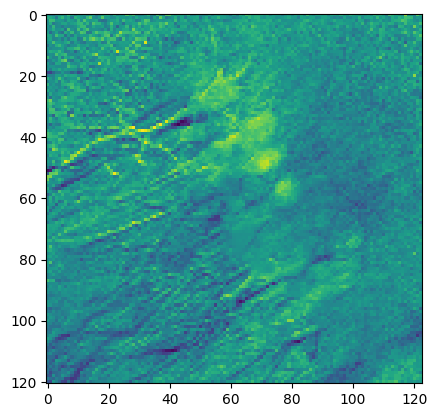

In [29]:
for l in labels.T:
    plt.imshow(l)

In [30]:
plt.show()

RFBOutputContext()

JupyterWgpuCanvas()
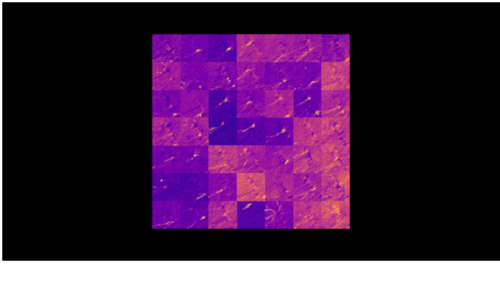

In [37]:
fig = fpl.Figure()

ix = 0
for i in range(7):
    for j in range(7):
        fig[0, 0].add_image(labels.T[ix], offset=(130 + (i * 123), 130 + (j * 121), 0))
        ix += 1

fig.show()